In [1]:
import control as ctrl
import numpy as np
import matplotlib.pyplot as plt

# Diseño del sistema de control del péndulo

Seguimos con el ejemplo de teoría, pero con un pequeño cambio:

In [2]:
w0=2
A=[[0,1],[-w0**2,0]]
B=[[0],[1]]
C=[1,0]
D=0

pendulo=ctrl.ss(A,B,C,D)
pendulo

StateSpace(
array([[ 0.,  1.],
       [-4.,  0.]]),
array([[0.],
       [1.]]),
array([[1., 0.]]),
array([[0.]]),
states=2, outputs=1, inputs=1)

## Obtención de la ley de control

Ubicamos los dos polos de la ley de control en $-2\omega_0$. Como son polos repetidos usamos `acker`, que devuelve un vector 1-D; lo convertimos en matriz fila para poder operar con él:

In [3]:
K=np.atleast_2d(ctrl.acker(pendulo.A,pendulo.B,[-2*w0,-2*w0]))
K

array([[12.,  8.]])

## Diseño del estimador completo

Ubicamos los polos del estimador en $-4\omega_0$:

In [4]:
L=np.atleast_2d(ctrl.acker(pendulo.A.T,pendulo.C.T,[-4*w0,-4*w0])).T
L

array([[16.],
       [60.]])

Verificamos los autovalores de la ley de control y del estimador:

In [5]:
np.linalg.eigvals(pendulo.A-pendulo.B@K)

array([-3.99999997, -4.00000003])

In [6]:
np.linalg.eigvals(pendulo.A-L@pendulo.C)

array([-7.99999993, -8.00000007])

## Definimos el sistema compensador (entrada $y$, salida $u$)

In [7]:
s=pendulo
Acomp=s.A-s.B@K-L@s.C
Bcomp=L
Ccomp=-K
comp=ctrl.ss(Acomp,Bcomp,Ccomp,0)
comp

StateSpace(
array([[-16.,   1.],
       [-76.,  -8.]]),
array([[16.],
       [60.]]),
array([[-12.,  -8.]]),
array([[0.]]),
states=2, outputs=1, inputs=1)

In [8]:
np.linalg.eigvals(comp.A)

array([-12.+7.74596669j, -12.-7.74596669j])

Vemos que los polos del compensador son estables.

In [9]:
comp.zeros()

array([-0.30952381+0.j])

Verificamos que los polos a lazo cerrado del sistema compensado son los adecuados:

In [10]:
sys_comp = ctrl.feedback(-s*comp)
sys_comp.poles()

array([-8.00000044+0.00000000e+00j, -7.99999956+0.00000000e+00j,
       -4.        +2.65155119e-07j, -4.        -2.65155119e-07j])

Los polos a lazo cerrado son la unión de los polos de la ley de control ($-2\omega_0$) y los del estimador ($-4\omega_0$), como predice el principio de separación.

## Sistema completo

Conectamos la planta y el compensador con `interconnect`, que une las señales que tienen el mismo nombre. La planta tiene entrada `u` y salida `y`; el compensador tiene entrada `y` y salida `uc`; y un sumador forma `u = uc + w`. Así el sistema conectado tiene una entrada auxiliar `w` (que en este caso dejamos en cero) y dos salidas: la salida de la planta `y` y el esfuerzo de control `uc`.

In [11]:
def lazo_cerrado(compensador):
    planta = ctrl.ss(s.A, s.B, s.C, s.D, inputs='u', outputs='y', name='planta')
    comp_n = ctrl.ss(compensador.A, compensador.B, compensador.C, compensador.D,
                     inputs='y', outputs='uc', name='compensador')
    suma = ctrl.summing_junction(inputs=['uc', 'w'], output='u', name='suma')
    return ctrl.interconnect([planta, comp_n, suma], inplist='w', outlist=['y', 'uc'])

Simulamos la respuesta a una condición inicial en la posición del péndulo (los dos primeros estados son los de la planta y los dos últimos los del compensador):

In [12]:
sys_completo = lazo_cerrado(comp)
t,y = ctrl.initial_response(sys_completo, X0=[1,0,0,0], T=np.linspace(0,3,1001))

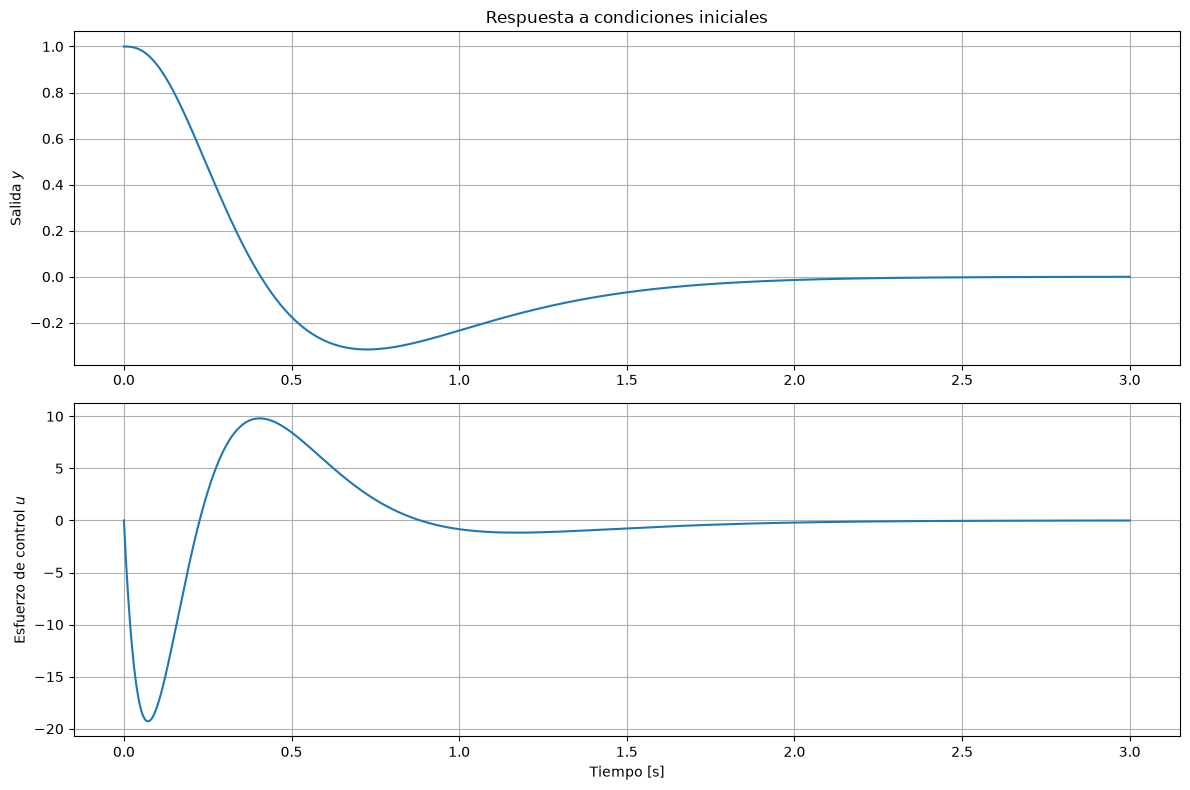

In [13]:
fig, ax = plt.subplots(2,1,figsize=(12,8))
ax[0].plot(t,y[0,:])
ax[0].set_title('Respuesta a condiciones iniciales')
ax[0].set_ylabel("Salida $y$")
ax[0].grid()
ax[1].plot(t,y[1,:])
ax[1].set_xlabel("Tiempo [s]")
ax[1].set_ylabel("Esfuerzo de control $u$")
ax[1].grid()
fig.tight_layout()

In [14]:
np.linalg.eigvals(sys_completo.A)

array([-8.        +3.30072092e-07j, -8.        -3.30072092e-07j,
       -4.00000025+0.00000000e+00j, -3.99999975+0.00000000e+00j])

## Ubicación óptima de los autovalores del estimador

Usamos el lugar simétrico de las raíces para el estimador. Para eso necesitamos la función de transferencia desde la entrada de ruido de proceso hasta la salida, $G_e(s) = \mathbf{C}(s\mathbf I - \mathbf A)^{-1}\mathbf B_1$. Suponemos que el ruido de proceso entra por el mismo lugar que la entrada de control, $\mathbf{B_1} = \mathbf{B}$:

In [15]:
B1=B

In [16]:
def conjugate_tf(G):
    """Devuelve G(-s) para un sistema SISO."""
    num = ctrl.tf(G).num[0][0]
    den = ctrl.tf(G).den[0][0]
    # el coeficiente i multiplica a s^(n-1-i)
    nume = [c*(-1)**(len(num)-1-i) for i, c in enumerate(num)]
    dene = [c*(-1)**(len(den)-1-i) for i, c in enumerate(den)]
    return ctrl.tf(nume, dene)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


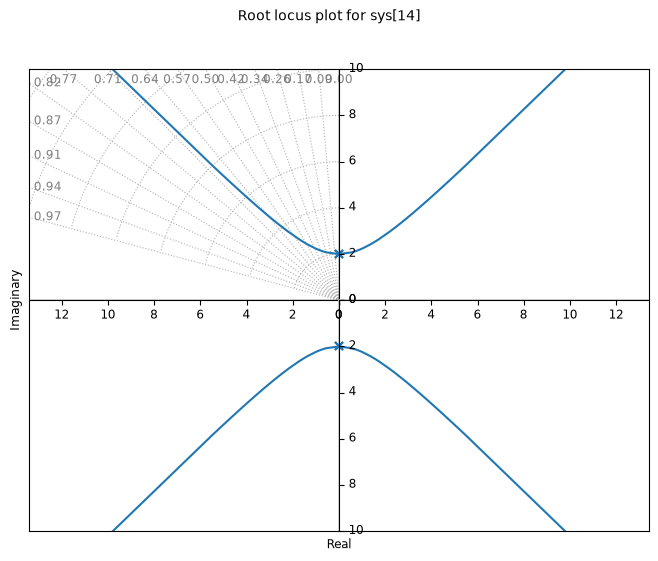

In [17]:
aux1 = ctrl.ss(A,B1,C,D)
aux2 = conjugate_tf(aux1)
G_srle = ctrl.tf(aux1)*aux2
ctrl.rlocus(G_srle, xlim=[-8,8], ylim=[-10,10]);  # aumentamos los límites para ver la zona donde queremos ubicar los polos
plt.gcf().set_size_inches(8,6)

Elegimos la ganancia del lugar simétrico (por ejemplo, haciendo clic sobre las ramas del gráfico interactivo) y obtenemos los polos estables correspondientes:

In [18]:
k = 8000
r = ctrl.root_locus_map(G_srle, gains=[k]).loci[0]
r

array([-6.53957633-6.83857138j, -6.53957633+6.83857138j,
        6.53957633-6.83857138j,  6.53957633+6.83857138j])

In [19]:
rsel = r[np.real(r)<0]
rsel

array([-6.53957633-6.83857138j, -6.53957633+6.83857138j])

In [20]:
L = ctrl.place(pendulo.A.T, pendulo.C.T, rsel).T
L

array([[13.07915266],
       [85.53211714]])

In [21]:
comp_srl = ctrl.ss(s.A-s.B@K-L@s.C, L, -K, 0)
comp_srl.poles()

array([-10.53957633+9.75103426j, -10.53957633-9.75103426j])

In [22]:
sys_completo_srl = lazo_cerrado(comp_srl)
t_srl, y_srl = ctrl.initial_response(sys_completo_srl, X0=[1,0,0,0], T=np.linspace(0,3,1001))

Comparamos las respuestas de los dos diseños:

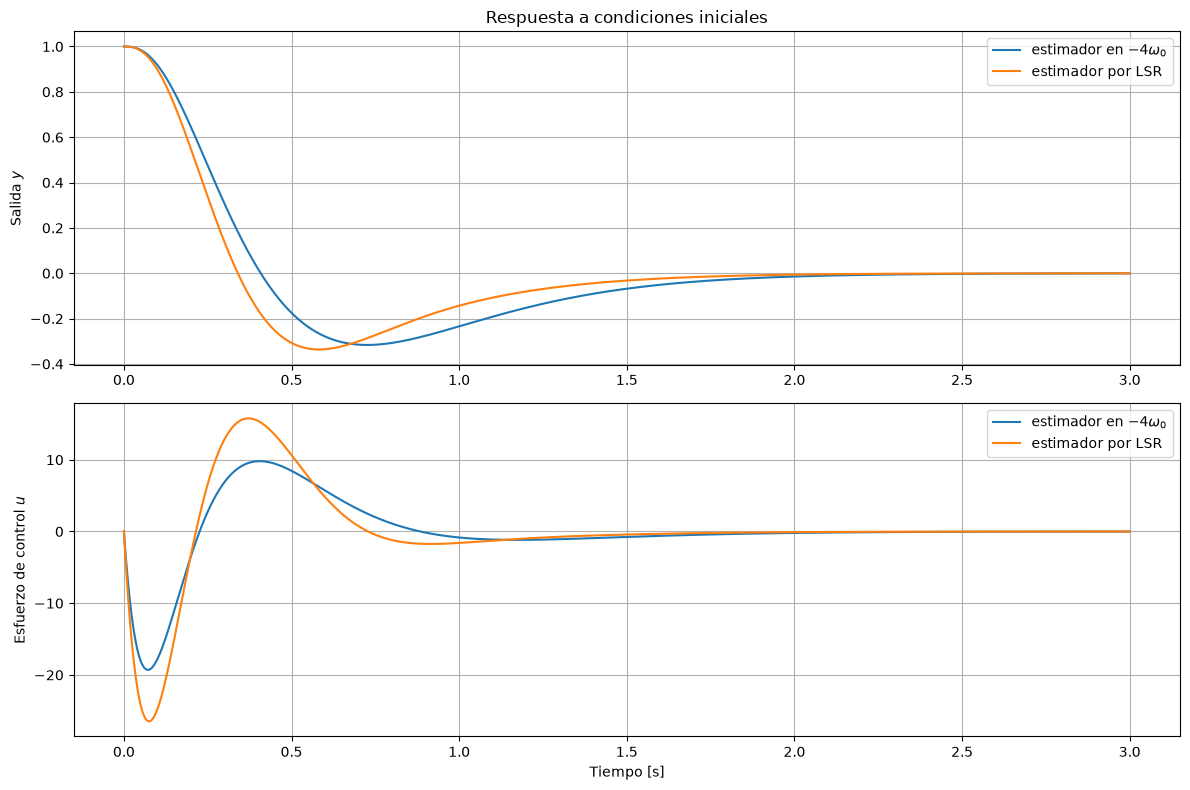

In [23]:
fig, ax = plt.subplots(2,1,figsize=(12,8))
ax[0].plot(t,y[0,:],label="estimador en $-4\\omega_0$")
ax[0].plot(t_srl,y_srl[0,:],label="estimador por LSR")
ax[0].set_title('Respuesta a condiciones iniciales')
ax[0].set_ylabel("Salida $y$")
ax[0].legend()
ax[0].grid()
ax[1].plot(t,y[1,:],label="estimador en $-4\\omega_0$")
ax[1].plot(t_srl,y_srl[1,:],label="estimador por LSR")
ax[1].set_xlabel("Tiempo [s]")
ax[1].set_ylabel("Esfuerzo de control $u$")
ax[1].legend()
ax[1].grid()
fig.tight_layout()